## 1. Import thư viện và mô hình

In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, log_loss
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong project chứa src/data.py và src/config.py.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
from src.models.softmax import SoftmaxRegression
print('scikit-learn:', sklearn.__version__)


scikit-learn: 1.9.1


## 2. Nạp dữ liệu và chia train/validation

In [2]:
SEED = 42
X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)

print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Nhãn train:', y_train.shape)
print('Miền pixel:', X_train.min(), X_train.max())
EPOCHS, BATCH_SIZE = 100, 256
BASE_L2 = 1 / len(X_train)


Train: (50000, 784) Validation: (10000, 784) Test: (10000, 784)
Nhãn train: (50000,)
Miền pixel: 0.0 1.0


## 3. Định nghĩa hàm đánh giá và chạy thí nghiệm

In [3]:
def metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision_macro=precision,
                recall_macro=recall, f1_macro=f1)

def experiment(values, parameter, learning_rate=0.1, l2=BASE_L2):
    models, rows = {}, []
    for value in values:
        params = dict(learning_rate=learning_rate, l2=l2)
        params[parameter] = value
        model = SoftmaxRegression(**params, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                 random_state=SEED, patience=None, verbose=False)
        t0 = time.perf_counter()
        model.fit(X_train, y_train, X_val, y_val)
        seconds = time.perf_counter() - t0
        p = model.predict_proba(X_val)
        models[value] = model
        rows.append({parameter: value, **metrics(y_val, p.argmax(1)),
            'val_CE': log_loss(y_val, p, labels=np.arange(10)),
            'train_accuracy': model.score(X_train, y_train),
            'weight_norm': np.linalg.norm(model.W_),
            'best_epoch': model.best_epoch_, 'fit_seconds': seconds})
        print(f'{parameter}={value:g}: val F1={rows[-1]["f1_macro"]:.4f}', flush=True)
    return models, pd.DataFrame(rows)

def plot_experiment(models, parameter):
    fig, ax = plt.subplots(figsize=(8, 4))
    for value, model in models.items():
        loss = model.history_['val_loss']
        ax.plot(range(1, len(loss) + 1), loss, label=f'{parameter}={value:g}')
    ax.set(xlabel='Epoch', ylabel='Validation cross-entropy', title=f'Ảnh hưởng của {parameter}')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def best_index(table):
    return table.sort_values(['f1_macro', 'val_CE'], ascending=[False, True]).index[0]

# Cùng 100 epoch; fit() vẫn khôi phục checkpoint validation CE tốt nhất.
# Chọn siêu tham số theo F1 macro, CE phá hòa; không dùng test.

## 4. Khảo sát learning rate

learning_rate=0.001: val F1=0.8742
learning_rate=0.01: val F1=0.9078
learning_rate=0.1: val F1=0.9202
learning_rate=0.5: val F1=0.9218
learning_rate=1: val F1=0.9216


,learning_rate,accuracy,precision_macro,recall_macro,f1_macro,val_CE,train_accuracy,weight_norm,best_epoch,fit_seconds
0,0.001,0.8760,0.87565,0.87399,0.87418,0.49735,0.87684,4.391210,100,31.54112
1,0.010,0.9087,0.90816,0.90767,0.90775,0.32657,0.91256,8.472590,100,29.42388
2,0.100,0.9211,0.92025,0.92023,0.92016,0.28524,0.92950,14.866900,96,33.53060
3,0.500,0.9228,0.92196,0.92187,0.92180,0.28371,0.93330,20.224739,58,34.07090
4,1.000,0.9227,0.92197,0.92167,0.92165,0.28894,0.93432,24.833570,58,32.20192


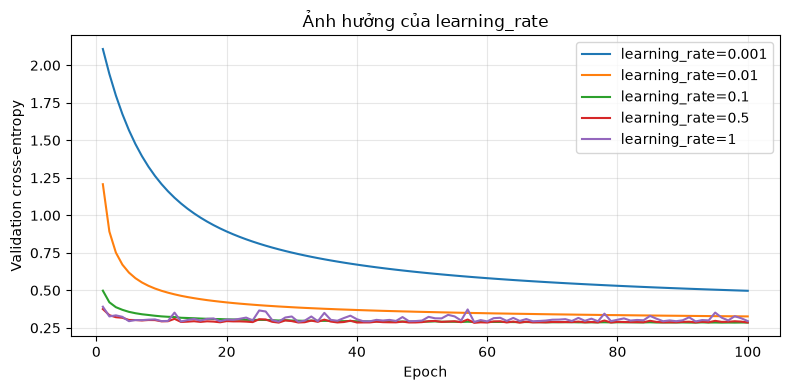

Learning rate được chọn: 0.5


In [4]:
lr_models, lr_results = experiment([0.001, 0.01, 0.1, 0.5, 1.0], 'learning_rate')
display(lr_results.round(5))
plot_experiment(lr_models, 'learning_rate')
best_lr = float(lr_results.loc[best_index(lr_results), 'learning_rate'])
print('Learning rate được chọn:', best_lr)

## 5. Khảo sát L2 

l2=0: val F1=0.9213
l2=1e-05: val F1=0.9216
l2=0.0001: val F1=0.9216
l2=0.001: val F1=0.9161


,l2,accuracy,precision_macro,recall_macro,f1_macro,val_CE,train_accuracy,weight_norm,best_epoch,fit_seconds
0,0.00000,0.9223,0.92142,0.92137,0.92129,0.28428,0.93392,20.963650,58,26.98985
1,0.00001,0.9226,0.92174,0.92166,0.92159,0.28397,0.93348,20.585711,58,28.16633
4,0.00002,0.9228,0.92196,0.92187,0.92180,0.28371,0.93330,20.224739,58,34.07090
2,0.00010,0.9226,0.92181,0.92166,0.92162,0.28296,0.93234,17.846670,58,36.11920
3,0.00100,0.9171,0.91647,0.91608,0.91608,0.30113,0.92154,10.314260,58,37.42076


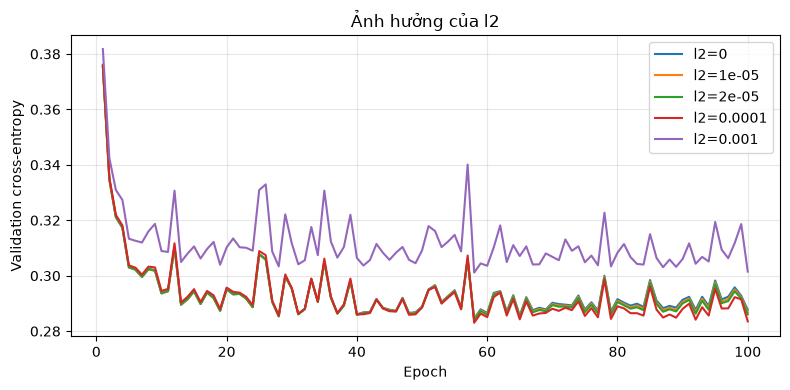

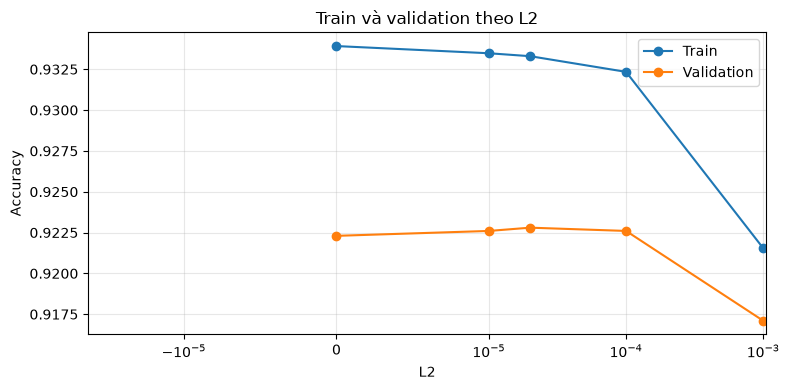

Chọn lr=0.5, L2=2e-05, checkpoint=58
Tổng thời gian tìm kiếm: 289.46s


In [5]:
# Tái sử dụng cấu hình L2 baseline đã chạy ở thí nghiệm learning rate.
l2_models, l2_results = experiment([0, 1e-5, 1e-4, 1e-3], 'l2', learning_rate=best_lr)
l2_models[BASE_L2] = lr_models[best_lr]
baseline = lr_results.loc[[best_index(lr_results)]].drop(columns='learning_rate').copy()
baseline['l2'] = BASE_L2
l2_results = pd.concat([l2_results, baseline], ignore_index=True).sort_values('l2')
display(l2_results.round(5))
plot_experiment(dict(sorted(l2_models.items())), 'l2')

ax = l2_results.plot(x='l2', y=['train_accuracy', 'accuracy'], marker='o', figsize=(8, 4))
ax.set_xscale('symlog', linthresh=1e-5)
ax.set(xlabel='L2', ylabel='Accuracy', title='Train và validation theo L2')
ax.legend(['Train', 'Validation']); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

best_row = l2_results.loc[best_index(l2_results)]
best_l2 = float(best_row['l2'])
manual, manual_time = l2_models[best_l2], float(best_row['fit_seconds'])
search_seconds = lr_results.fit_seconds.sum() + l2_results.loc[l2_results.l2 != BASE_L2, 'fit_seconds'].sum()
print(f'Chọn lr={best_lr:g}, L2={best_l2:g}, checkpoint={manual.best_epoch_}')
print(f'Tổng thời gian tìm kiếm: {search_seconds:.2f}s')
# Đây là tìm kiếm tuần tự LR rồi L2, không phải tìm mọi tổ hợp LR × L2.

## 6. Theo dõi loss và accuracy theo epoch

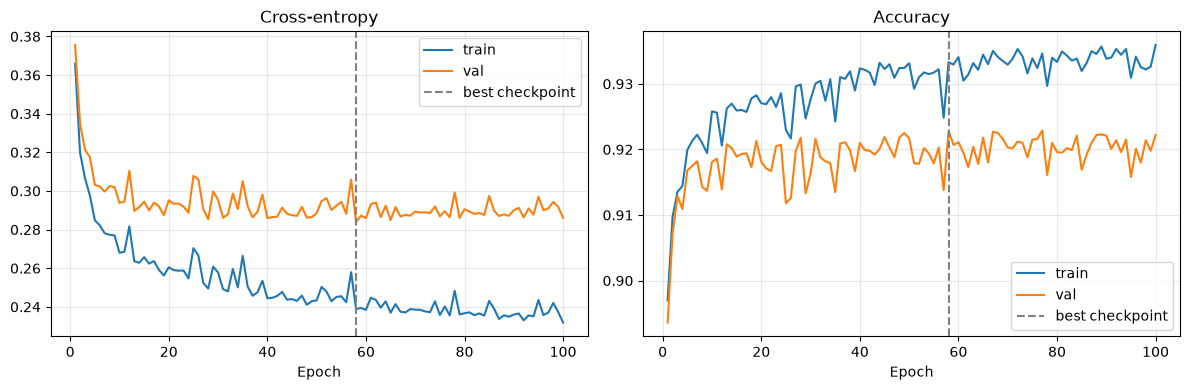

In [6]:
h = manual.history_
epochs = np.arange(1, len(h['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ['train', 'val']:
    axes[0].plot(epochs, h[f'{split}_loss'], label=split)
    axes[1].plot(epochs, h[f'{split}_accuracy'], label=split)
for ax, title in zip(axes, ['Cross-entropy', 'Accuracy']):
    ax.axvline(manual.best_epoch_, color='gray', linestyle='--', label='best checkpoint')
    ax.set(xlabel='Epoch', title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Huấn luyện mô hình sklearn với L2 tương ứng

In [7]:
# mean CE + L2/2 * ||W||²; không phạt bias, không dùng trọng số mẫu/lớp.
# SGD và L-BFGS khác optimizer/điều kiện dừng, không suy ra hiệu quả cài đặt từ thời gian.
C = 1 / (best_l2 * len(X_train)) if best_l2 > 0 else np.inf
reference = LogisticRegression(C=C, solver='lbfgs', max_iter=300, tol=1e-4)
t0 = time.perf_counter()
reference.fit(X_train, y_train)  # Giữ cảnh báo nếu chưa hội tụ.
reference_time = time.perf_counter() - t0
print(f'C={C:g}; fit={reference_time:.2f}s; iterations={reference.n_iter_}')

C=1; fit=984.79s; iterations=[259]


## 8. Đánh giá hai mô hình trên train, validation và test

,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,Softmax tự viết,Train,0.9333,0.9325,0.9323,0.9323,34.0709,0.0428
1,Softmax tự viết,Validation,0.9228,0.9220,0.9219,0.9218,34.0709,0.0047
2,Softmax tự viết,Test,0.9253,0.9244,0.9241,0.9241,34.0709,0.0096
3,Softmax sklearn,Train,0.9402,0.9395,0.9394,0.9394,984.7911,0.0798
4,Softmax sklearn,Validation,0.9217,0.9208,0.9207,0.9207,984.7911,0.0130
5,Softmax sklearn,Test,0.9241,0.9232,0.9230,0.9230,984.7911,0.0118


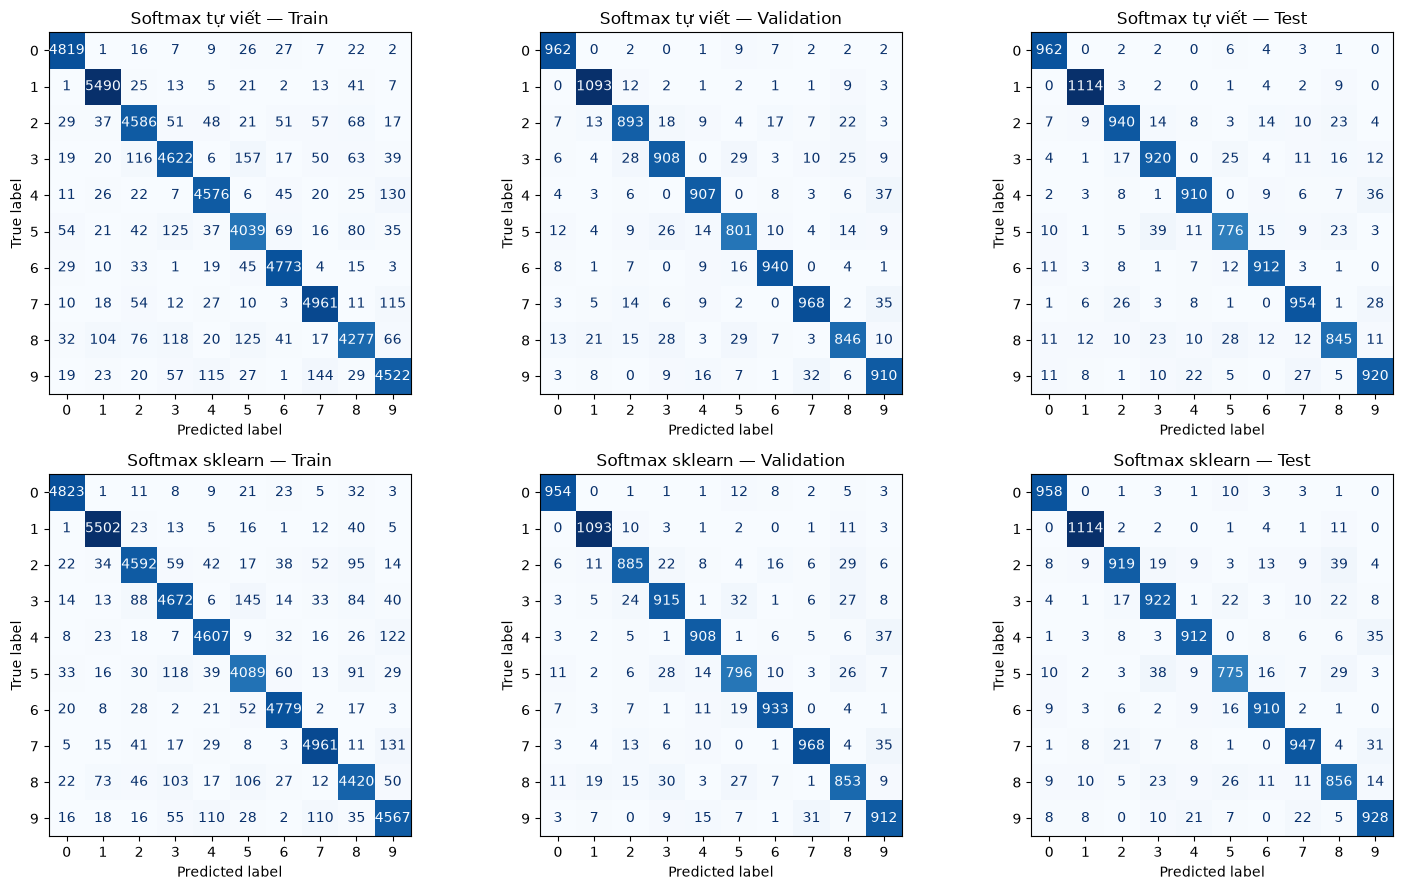

In [8]:
models = {'Softmax tự viết': manual, 'Softmax sklearn': reference}
datasets = {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}
rows, predictions = [], {}
for name, model in models.items():
    for split, (X, y) in datasets.items():
        t0 = time.perf_counter()
        pred = model.predict_proba(X).argmax(1)
        seconds = time.perf_counter() - t0
        predictions[name, split] = pred
        rows.append({'model': name, 'split': split, **metrics(y, pred),
            'fit_seconds': manual_time if name == 'Softmax tự viết' else reference_time,
            'predict_seconds': seconds})
results = pd.DataFrame(rows)
display(results.round(4))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, name in enumerate(models):
    for col, (split, (_, y)) in enumerate(datasets.items()):
        ConfusionMatrixDisplay.from_predictions(y, predictions[name, split], labels=np.arange(10),
            ax=axes[row, col], cmap='Blues', colorbar=False, values_format='d')
        axes[row, col].set_title(f'{name} — {split}')
plt.tight_layout(); plt.show()

## 9. Trực quan trọng số và phân tích lỗi trên test

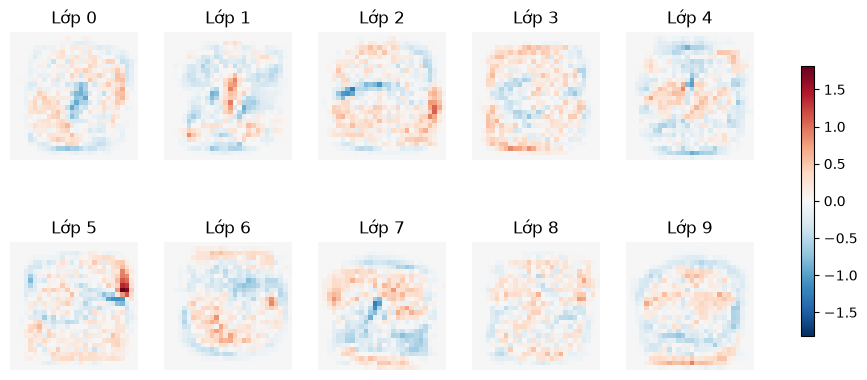

Độ đo theo chữ số trên test:


,precision,recall,f1-score,support
0,0.9441,0.9816,0.9625,980.0
1,0.9628,0.9815,0.9721,1135.0
2,0.9216,0.9109,0.9162,1032.0
3,0.9064,0.9109,0.9086,1010.0
4,0.9324,0.9267,0.9295,982.0
5,0.9055,0.8700,0.8874,892.0
6,0.9363,0.9520,0.9441,958.0
7,0.9200,0.9280,0.9240,1028.0
8,0.9076,0.8676,0.8871,974.0
9,0.9073,0.9118,0.9095,1009.0


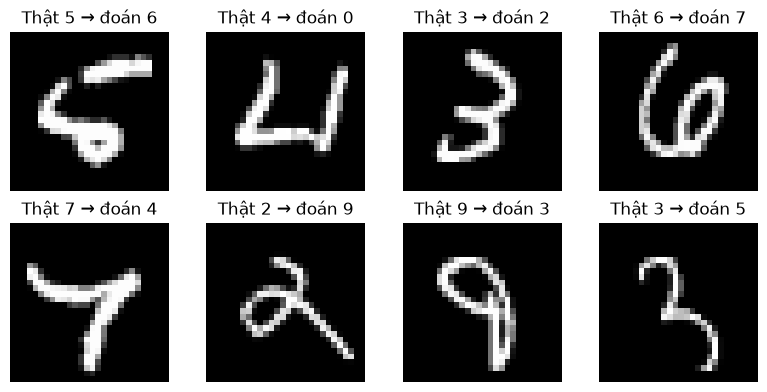

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
v = abs(manual.W_).max()
for k, ax in enumerate(axes.flat):
    im = ax.imshow(manual.W_[:, k].reshape(28, 28), cmap='RdBu_r', vmin=-v, vmax=v)
    ax.set_title(f'Lớp {k}'); ax.axis('off')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7)
plt.show()
pred = predictions['Softmax tự viết', 'Test']
report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
print('Độ đo theo chữ số trên test:')
display(report.loc[[str(k) for k in range(10)]].round(4))
wrong = np.flatnonzero(pred != y_test)[:8]
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax in axes.flat: ax.axis('off')
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Thật {y_test[i]} → đoán {pred[i]}')
plt.tight_layout(); plt.show()

## 10. Xuất kết quả cho báo cáo và bảng so sánh chung

In [10]:
OUTPUT = ROOT / 'results' / 'softmax'
OUTPUT.mkdir(parents=True, exist_ok=True)
for name, table in {'metrics': results, 'learning_rate': lr_results, 'l2': l2_results,
                    'history': pd.DataFrame(manual.history_)}.items():
    table.to_csv(OUTPUT / f'{name}.csv', index=False)
results.query("model == 'Softmax tự viết' and split == 'Test'").to_csv(OUTPUT / 'comparison.csv', index=False)
np.savez_compressed(OUTPUT / 'manual_weights.npz', W=manual.W_, b=manual.b_)
config = dict(learning_rate=best_lr, l2=best_l2, epochs=EPOCHS, batch_size=BATCH_SIZE,
              seed=SEED, best_epoch=int(manual.best_epoch_), search_seconds=float(search_seconds))
(OUTPUT / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
print('Số tham số:', manual.W_.size + manual.b_.size)
print('Đã lưu:', OUTPUT)

Số tham số: 7850
Đã lưu: d:\midterm_pattern_recognition\mnist-pattern-recognition\results\softmax
